# Regresion Lineal: Caso Costo de Seguro Medico

Aplicación de la regresion lineal multiple al conjunto de datos [Medical Cost Personal Datasets](https://www.kaggle.com/datasets/mirichoi0218/insurance/data) para predecir el costo anual del seguro medico (`charges`) a partir de variables demograficas y de salud.

## 1. Configuracion del entorno

Importacion de las librerias necesarias y configuracion del estilo de las graficas.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# Estilo de graficas
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.0)
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 110,
})

print("numpy", np.__version__, "| pandas", pd.__version__)

numpy 2.4.4 | pandas 3.0.3


## 2. Carga de la data

Exploración del dataset, el cuál contiene 1,338 registros de asegurados en Estados Unidos con 7 variables: edad, sexo, indice de masa corporal (BMI), numero de hijos, condicion de fumador, region y el costo anual del seguro.

In [2]:
df = pd.read_csv("insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [4]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [5]:
print("Valores nulos por columna:")
print(df.isnull().sum())
print(f"\nFilas duplicadas: {df.duplicated().sum()}")

Valores nulos por columna:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Filas duplicadas: 1


## 3. Exploración

Visualización de la distribucion de la variable objetivo y su relacion con las principales variables predictoras.

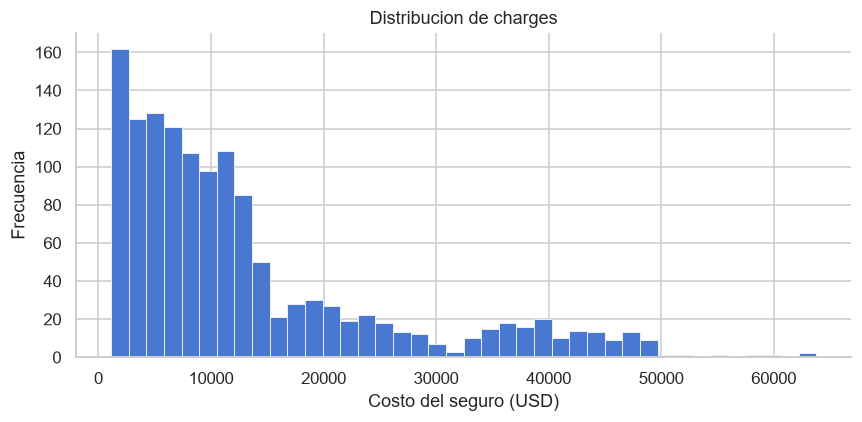

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df["charges"], bins=40, edgecolor="white", linewidth=0.5)
ax.set_xlabel("Costo del seguro (USD)")
ax.set_ylabel("Frecuencia")
ax.set_title("Distribucion de charges")
plt.tight_layout()
plt.show()

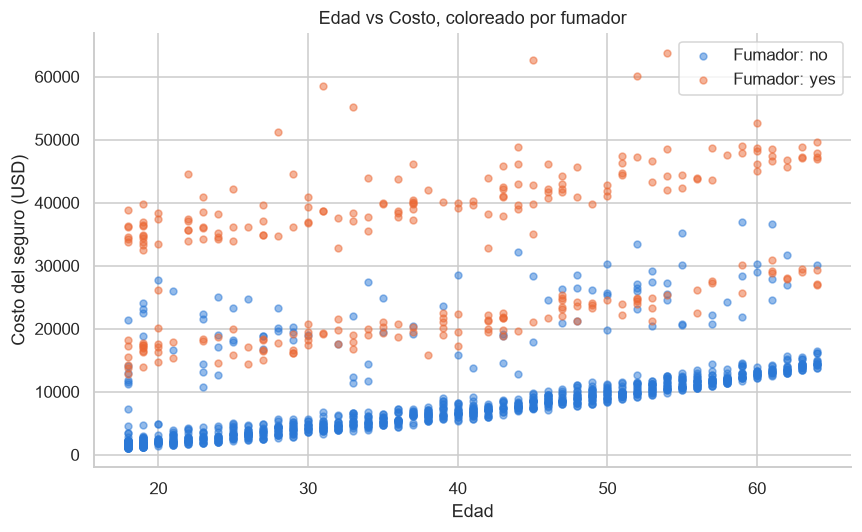

In [7]:
colors = {"yes": "#eb6834", "no": "#2a78d6"}

fig, ax = plt.subplots(figsize=(8, 5))
for label, group in df.groupby("smoker"):
    ax.scatter(group["age"], group["charges"], alpha=0.5, s=20,
               label=f"Fumador: {label}", color=colors[label])
ax.set_xlabel("Edad")
ax.set_ylabel("Costo del seguro (USD)")
ax.set_title("Edad vs Costo, coloreado por fumador")
ax.legend()
plt.tight_layout()
plt.show()

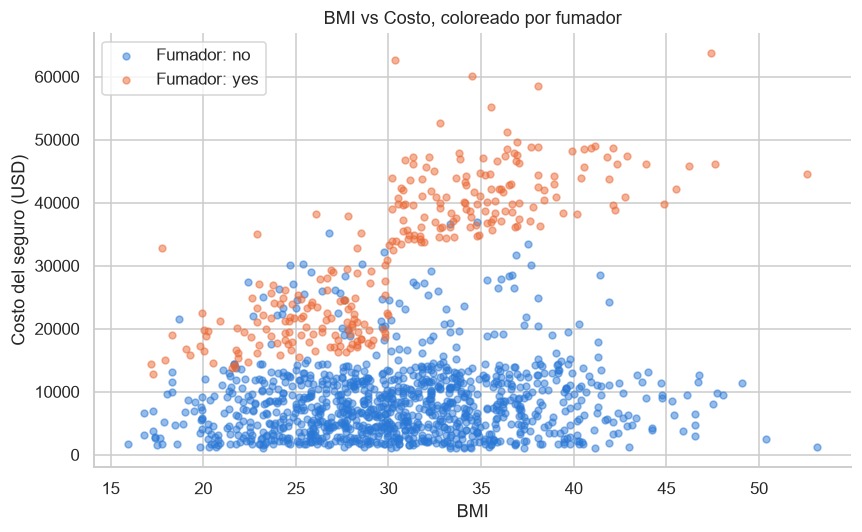

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
for label, group in df.groupby("smoker"):
    ax.scatter(group["bmi"], group["charges"], alpha=0.5, s=20,
               label=f"Fumador: {label}", color=colors[label])
ax.set_xlabel("BMI")
ax.set_ylabel("Costo del seguro (USD)")
ax.set_title("BMI vs Costo, coloreado por fumador")
ax.legend()
plt.tight_layout()
plt.show()

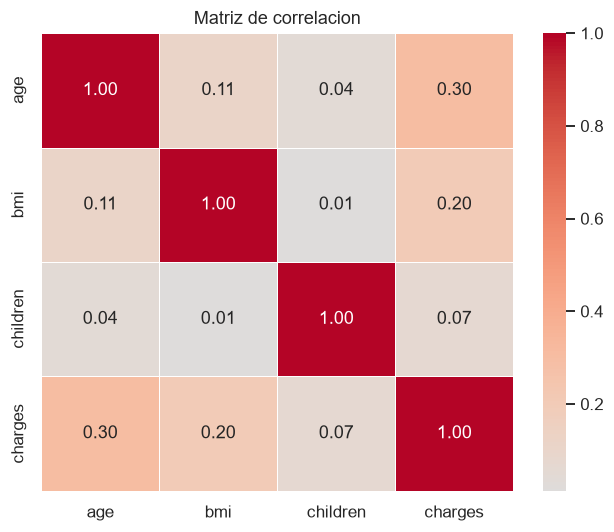

In [9]:
numeric_cols = df.select_dtypes(include="number")
corr = numeric_cols.corr()

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, ax=ax)
ax.set_title("Matriz de correlacion")
plt.tight_layout()
plt.show()

**Observaciones:**

- La distribucion de `charges` esta sesgada a la derecha: la mayoria de los costos son bajos, con una cola larga de valores altos.
- Fumar es el factor visual mas claro: los fumadores forman un grupo diferenciado con costos significativamente mayores.
- La edad muestra una relacion positiva con el costo; en fumadores, esa pendiente es mas pronunciada.
- El BMI tiene una relacion menos lineal con el costo en no fumadores, pero en fumadores con BMI alto los costos se disparan.
- La correlacion numerica mas fuerte con `charges` es `age` seguida de `bmi`.

## 4. Procesamiento

Se elimina la fila duplicada, luego, aplicamos codificacion one-hot a las variables categoricas y separamos los conjuntos de entrenamiento y prueba utilizando la partición 80/20.

In [10]:
# Eliminar duplicados
df = df.drop_duplicates()
print(f"Registros tras eliminar duplicados: {len(df)}")

# Codificacion one-hot (drop_first para evitar multicolinealidad)
df_encoded = pd.get_dummies(df, columns=["sex", "smoker", "region"], drop_first=True)
df_encoded.head()

Registros tras eliminar duplicados: 1337


,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,False,True,False,False,True
1,18,33.770,1,1725.55230,True,False,False,True,False
2,28,33.000,3,4449.46200,True,False,False,True,False
3,33,22.705,0,21984.47061,True,False,True,False,False
4,32,28.880,0,3866.85520,True,False,True,False,False


In [11]:
# Separar features (X) y variable objetivo (y)
X = df_encoded.drop("charges", axis=1)
y = df_encoded["charges"]

# Particion del dataset80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print(f"Train: {X_train.shape[0]} | Test: {X_test.shape[0]}")

Train: 1069 | Test: 268


## 5. Entrenamiento y evaluación

Entrenamiento del algoritmo de regresion lineal con scikit-learn y evaluación del modelo con métricas de rendimiento con R^2, MAE y RMSE.

In [12]:
model = LinearRegression() # Instanciación del algoritmo de Regresión Lineal
model.fit(X_train, y_train) # Se entrena el algoritmo con el conjunto de datos de entrenamiento y de evaluación

y_pred = model.predict(X_test) # Se realiza las predicciones del modelo ya entrenado con los datos de entrenamiento

In [18]:
# Indica el porcentaje de la variabilidad de los datos que logra explicar el modelo.
# Es decir, 
r2 = r2_score(y_test, y_pred)

# Realiza el calculo del promedio de la diferencia absoluta entre lo real y lo predicho.
# Es decir, 
mae = mean_absolute_error(y_test, y_pred)

# Es una métrica que mantiene el nivel de tolerancia del modelo
# ante errores grandes entre lo que predice y lo real.
# Basicamente 
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R²   : {r2:.4f}")
print(f"MAE  : {mae:,.2f} USD")
print(f"RMSE : {rmse:,.2f} USD")

R²   : 0.8069
MAE  : 4,177.05 USD
RMSE : 5,956.34 USD


## 6. Explicacion de la tecnica

La regresion lineal modela la relacion entre las variables de entrada y la salida con una ecuacion de la forma:

$$y = b_0 + b_1 x_1 + b_2 x_2 + \dots + b_m x_m$$

Donde $b_0$ es el intercepto y cada $b_i$ es el coeficiente que indica cuanto cambia $y$ por cada unidad de cambio en $x_i$.

**Minimos cuadrados:** el algoritmo busca la combinacion de coeficientes que minimiza la suma de las distancias al cuadrado entre los valores reales y los predichos.

**Supuestos principales:**

- **Linealidad:** la relacion entre cada variable y la salida es aproximadamente lineal.
- **Residuos normales:** los errores del modelo siguen una distribucion aproximadamente normal.
- **Homocedasticidad:** la varianza de los errores es constante a lo largo del rango de predicciones.

El grafico de residuos permite evaluar visualmente estos supuestos.

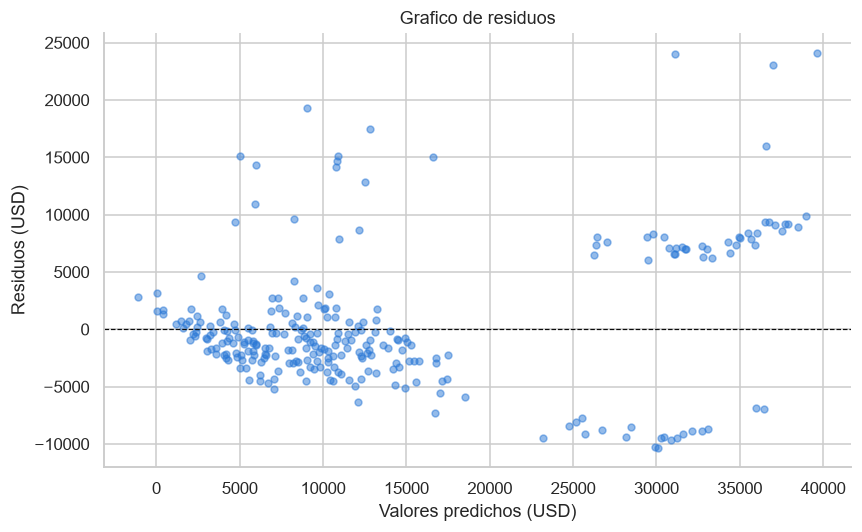

In [14]:
residuals = y_test - y_pred

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(y_pred, residuals, alpha=0.5, s=20, color="#2a78d6")
ax.axhline(0, color="#0b0b0b", linewidth=0.8, linestyle="--")
ax.set_xlabel("Valores predichos (USD)")
ax.set_ylabel("Residuos (USD)")
ax.set_title("Grafico de residuos")
plt.tight_layout()
plt.show()

## 7. Evaluación de impacto de cada variable en el modelo

Interpretación de los coeficientes del modelo para entender el impacto de cada variable sobre el costo del seguro.

In [15]:
coef_df = pd.DataFrame({
    "Variable": X.columns,
    "Coeficiente (USD)": model.coef_
})
coef_df.loc[len(coef_df)] = ["Intercepto", model.intercept_]
coef_df["Coeficiente (USD)"] = coef_df["Coeficiente (USD)"].round(2)
coef_df = coef_df.sort_values("Coeficiente (USD)", ascending=False, key=abs)
coef_df = coef_df.reset_index(drop=True)
coef_df

,Variable,Coeficiente (USD)
0,smoker_yes,23077.76
1,Intercepto,-11092.65
2,region_southeast,-838.92
3,region_southwest,-659.14
4,children,533.01
5,region_northwest,-391.76
6,bmi,318.70
7,age,248.21
8,sex_male,-101.54


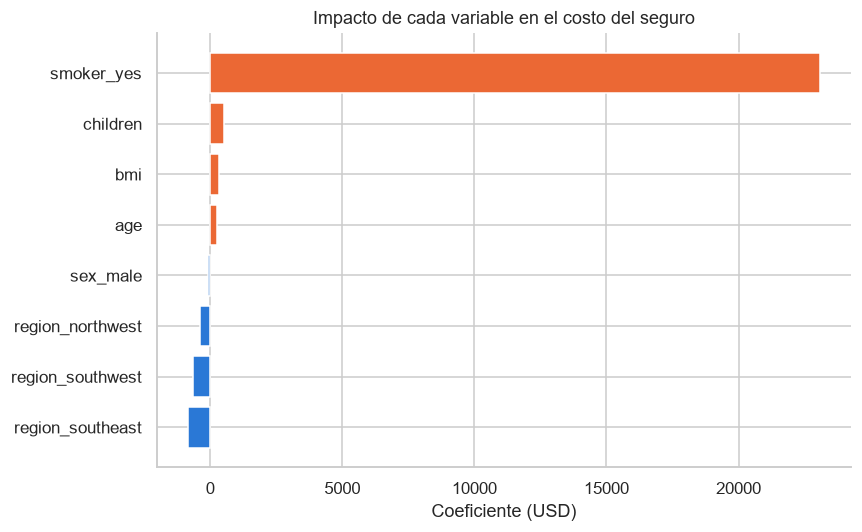

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
data = coef_df[coef_df["Variable"] != "Intercepto"].sort_values("Coeficiente (USD)")
colors_bar = ["#eb6834" if v > 0 else "#2a78d6" for v in data["Coeficiente (USD)"]]
ax.barh(data["Variable"], data["Coeficiente (USD)"], color=colors_bar, edgecolor="white")
ax.set_xlabel("Coeficiente (USD)")
ax.set_title("Impacto de cada variable en el costo del seguro")
plt.tight_layout()
plt.show()

### Interpretacion de los coeficientes

Cada coeficiente representa el cambio esperado en el costo anual del seguro (en dolares) cuando esa variable aumenta en una unidad, manteniendo las demas constantes.

- **smoker_yes:** es el factor con mayor impacto. Ser fumador incrementa el costo del seguro en aproximadamente el valor de su coeficiente, superando por mucho al resto de variables. Esto refleja el riesgo medico asociado al tabaquismo.
- **age:** por cada ano adicional de edad, el costo del seguro aumenta. Esto es coherente con el incremento del riesgo medico a mayor edad.
- **bmi:** un punto adicional de IMC incrementa el costo. Valores altos de BMI se asocian con mayor probabilidad de enfermedades cronicas.
- **children:** cada hijo dependiente adicional suma un monto moderado al costo.
- **sex_male, region_*:** estas variables tienen un impacto menor. Las diferencias regionales y de sexo existen pero son pequenas comparadas con fumar, la edad y el BMI.